# Lung fibrosis (GSE250346): s carries lesion context and the gradient toward fibrotic lesions

Unaffected vs fibrotic lung cores (Xenium, 343 genes). Ground truth for intra-fibrosis heterogeneity is the
pathologist H&E region annotation released with GSE250346. All z/s comparisons use fibrosis-arm cells only.

Main results: within fibrotic cores s separates H&E regions better than z in 75/109 region pairs; along the distance
to the nearest lesion, s predicts proximity better than z in 94/139 (supervised) cell type × core strata. Strongest
case: alveolar fibroblasts approaching fibroblastic foci (spatial-shift null p = 0.005; collagen/POSTN/CTHRC1 up).
Disease stage (Less vs More Affected) is carried by z, not s.

In [1]:
import sys; sys.path.insert(0, '/home/yancui/haruka_v2/notebooks')
from repro import run, require, show, STAGES, H, PY
# Default: figure stage only (redraw from saved analysis outputs). Turn on earlier stages to rerun them.
# Fresh machine: STAGES.update(download=True) fetches the preprocessed inputs (section 0), then fit=True, analysis=True.
# STAGES.update(download=True, fit=True, analysis=True)
print(STAGES)

{'download': False, 'data': False, 'fit': False, 'analysis': False, 'figure': True}


## 0 Preprocessed data (Hugging Face)

Skip the data stage: download the ready-to-fit inputs from [C1vy/haruka_v2_data](https://huggingface.co/datasets/C1vy/haruka_v2_data) and link them to the paths the scripts expect.

In [2]:
# C1vy/haruka_v2_data/06_fibrosis/gse250346_unaffected_vs_all_fibrosis.h5ad  ->  bench_lung_fibrosis_gse250346/data/gse250346_unaffected_vs_all_fibrosis.h5ad
# C1vy/haruka_v2_data/06_fibrosis/he_annot_matched.csv.gz  ->  /project/zhihuanglab/yancui/haruka_fibrosis_he/he_annot_matched.csv.gz
DL = H / "hf_data"
run(f'hf download C1vy/haruka_v2_data 06_fibrosis/gse250346_unaffected_vs_all_fibrosis.h5ad --repo-type dataset --local-dir {DL} && mkdir -p $(dirname bench_lung_fibrosis_gse250346/data/gse250346_unaffected_vs_all_fibrosis.h5ad) && ln -sfn {DL}/06_fibrosis/gse250346_unaffected_vs_all_fibrosis.h5ad bench_lung_fibrosis_gse250346/data/gse250346_unaffected_vs_all_fibrosis.h5ad', 'download')
run(f'hf download C1vy/haruka_v2_data 06_fibrosis/he_annot_matched.csv.gz --repo-type dataset --local-dir {DL} && mkdir -p $(dirname /project/zhihuanglab/yancui/haruka_fibrosis_he/he_annot_matched.csv.gz) && ln -sfn {DL}/06_fibrosis/he_annot_matched.csv.gz /project/zhihuanglab/yancui/haruka_fibrosis_he/he_annot_matched.csv.gz', 'download')

[skip: download stage off] hf download C1vy/haruka_v2_data 06_fibrosis/gse250346_unaffected_vs_all_fibrosis.h5ad --repo-type dataset --local-dir /home/yancui/haruka_v2/hf_data && mkdir -p $(dirname bench_lung_fibrosis_gse250346/data/gse250346_unaffected_vs_all_fibrosis.h5ad) && ln -sfn /home/yancui/haruka_v2/hf_data/06_fibrosis/gse250346_unaffected_vs_all_fibrosis.h5ad bench_lung_fibrosis_gse250346/data/gse250346_unaffected_vs_all_fibrosis.h5ad
[skip: download stage off] hf download C1vy/haruka_v2_data 06_fibrosis/he_annot_matched.csv.gz --repo-type dataset --local-dir /home/yancui/haruka_v2/hf_data && mkdir -p $(dirname /project/zhihuanglab/yancui/haruka_fibrosis_he/he_annot_matched.csv.gz) && ln -sfn /home/yancui/haruka_v2/hf_data/06_fibrosis/he_annot_matched.csv.gz /project/zhihuanglab/yancui/haruka_fibrosis_he/he_annot_matched.csv.gz


## 1 Data: download, export from the Seurat RDS (R), build the h5ad

In [3]:
run(f'wget -c -O bench_lung_fibrosis_gse250346/data/GSE250346_corrected.rds https://ftp.ncbi.nlm.nih.gov/geo/series/GSE250nnn/GSE250346/suppl/GSE250346_Seurat_GSE250346_CORRECTED_SEE_RDS_README_082024.rds', 'data')
run(f'/home/yancui/.conda/envs/milabo/bin/Rscript bench_lung_fibrosis_gse250346/export_gse250346_unaffected_vs_fibrosis.R bench_lung_fibrosis_gse250346/data/GSE250346_corrected.rds bench_lung_fibrosis_gse250346/data/export_unaffected_vs_fibrosis', 'data')
run(f'{PY} bench_lung_fibrosis_gse250346/build_h5ad.py --export-dir bench_lung_fibrosis_gse250346/data/export_unaffected_vs_fibrosis --out bench_lung_fibrosis_gse250346/data/gse250346_unaffected_vs_all_fibrosis.h5ad --contrast unaffected-vs-fibrosis', 'data')

[skip: data stage off] wget -c -O bench_lung_fibrosis_gse250346/data/GSE250346_corrected.rds https://ftp.ncbi.nlm.nih.gov/geo/series/GSE250nnn/GSE250346/suppl/GSE250346_Seurat_GSE250346_CORRECTED_SEE_RDS_README_082024.rds
[skip: data stage off] /home/yancui/.conda/envs/milabo/bin/Rscript bench_lung_fibrosis_gse250346/export_gse250346_unaffected_vs_fibrosis.R bench_lung_fibrosis_gse250346/data/GSE250346_corrected.rds bench_lung_fibrosis_gse250346/data/export_unaffected_vs_fibrosis
[skip: data stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_lung_fibrosis_gse250346/build_h5ad.py --export-dir bench_lung_fibrosis_gse250346/data/export_unaffected_vs_fibrosis --out bench_lung_fibrosis_gse250346/data/gse250346_unaffected_vs_all_fibrosis.h5ad --contrast unaffected-vs-fibrosis


## 2 H&E annotations (GEO supplementary) matched to cells by barcode + centroid

In [4]:
HE = '/project/zhihuanglab/yancui/haruka_fibrosis_he'
run(f'mkdir -p {HE}/raw {HE}/x && cd {HE}/raw && curl -sSLO https://ftp.ncbi.nlm.nih.gov/geo/series/GSE250nnn/GSE250346/suppl/GSE250346_HE_annotations.tar.gz && tar -xzf GSE250346_HE_annotations.tar.gz -C ../x', 'data')
run(f'{PY} bench_lung_fibrosis_gse250346/match_he_annotations.py', 'data')

[skip: data stage off] mkdir -p /project/zhihuanglab/yancui/haruka_fibrosis_he/raw /project/zhihuanglab/yancui/haruka_fibrosis_he/x && cd /project/zhihuanglab/yancui/haruka_fibrosis_he/raw && curl -sSLO https://ftp.ncbi.nlm.nih.gov/geo/series/GSE250nnn/GSE250346/suppl/GSE250346_HE_annotations.tar.gz && tar -xzf GSE250346_HE_annotations.tar.gz -C ../x
[skip: data stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_lung_fibrosis_gse250346/match_he_annotations.py


## 3 Fit (default model; batch = core; ~6.8 h on one GPU)

In [5]:
run('bash bench_real_discovery/run_all_compgated_samplebatch_sepheads.sh large_lung', 'fit')

[skip: fit stage off] bash bench_real_discovery/run_all_compgated_samplebatch_sepheads.sh large_lung


In [6]:
require(H / 'results_real_compgated_nb_final/gse250346_unaffected_vs_all_fibrosis/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0/background.npy', H / 'results_real_compgated_nb_final/gse250346_unaffected_vs_all_fibrosis/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0/salient.npy', '/project/zhihuanglab/yancui/haruka_fibrosis_he/he_annot_matched.csv.gz')

inputs present


True

## 4 Analyses (`zs_stage/`)
* `he_region_zs.py`: per H&E region pair, separability by z vs s (panel e)
* `he_region_spatial.py`: the same against a spatial-shift null (panel f)
* `lesion_gradient.py`: supervised proximity-to-lesion gradient, z vs s per cell type × core (panel g)
* `lesion_gradient_unsup.py`: unsupervised PC1/PC2/DPT axes vs lesion distance (panel h)
* `lesion_cases.py`: deep dive on the strongest cases, genes and spatial-shift nulls (panels j, k)

In [7]:
Z = 'bench_lung_fibrosis_gse250346/zs_stage'
run(f'{PY} he_region_zs.py', 'analysis', cwd=H / Z, log='he_region/run.out')
run(f'{PY} he_region_spatial.py', 'analysis', cwd=H / Z, log='he_region/spatial.out')
run(f'{PY} lesion_gradient.py', 'analysis', cwd=H / Z, log='lesion_gradient/run.out')
run(f'{PY} lesion_gradient_unsup.py', 'analysis', cwd=H / Z, log='lesion_gradient/unsup.out')
run(f'mkdir -p lesion_gradient/cases && {PY} lesion_cases.py', 'analysis', cwd=H / Z, log='lesion_gradient/cases/run.out')

[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python he_region_zs.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python he_region_spatial.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python lesion_gradient.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python lesion_gradient_unsup.py
[skip: analysis stage off] mkdir -p lesion_gradient/cases && /home/yancui/.conda/envs/haruka2/bin/python lesion_cases.py


## 5 Figure data (example core TILD117MA1, global UMAPs) and the figure

In [8]:
F = H / 'figures_paper/fibrosis'
run(f'{PY} fib_fig_data.py', 'analysis', cwd=F, env={'EXAMPLE_CORE': 'TILD117MA1'})
run(f'{PY} fib_umap_data.py', 'analysis', cwd=F)
run(f'{PY} make_fibrosis_figure.py', 'figure', cwd=F)

[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python fib_fig_data.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python fib_umap_data.py


panels 16 | fonts below minimum: []
full page (2282, 2009)
[figure] exit 0 in 8s: /home/yancui/.conda/envs/haruka2/bin/python make_fibrosis_figure.py


## Figure

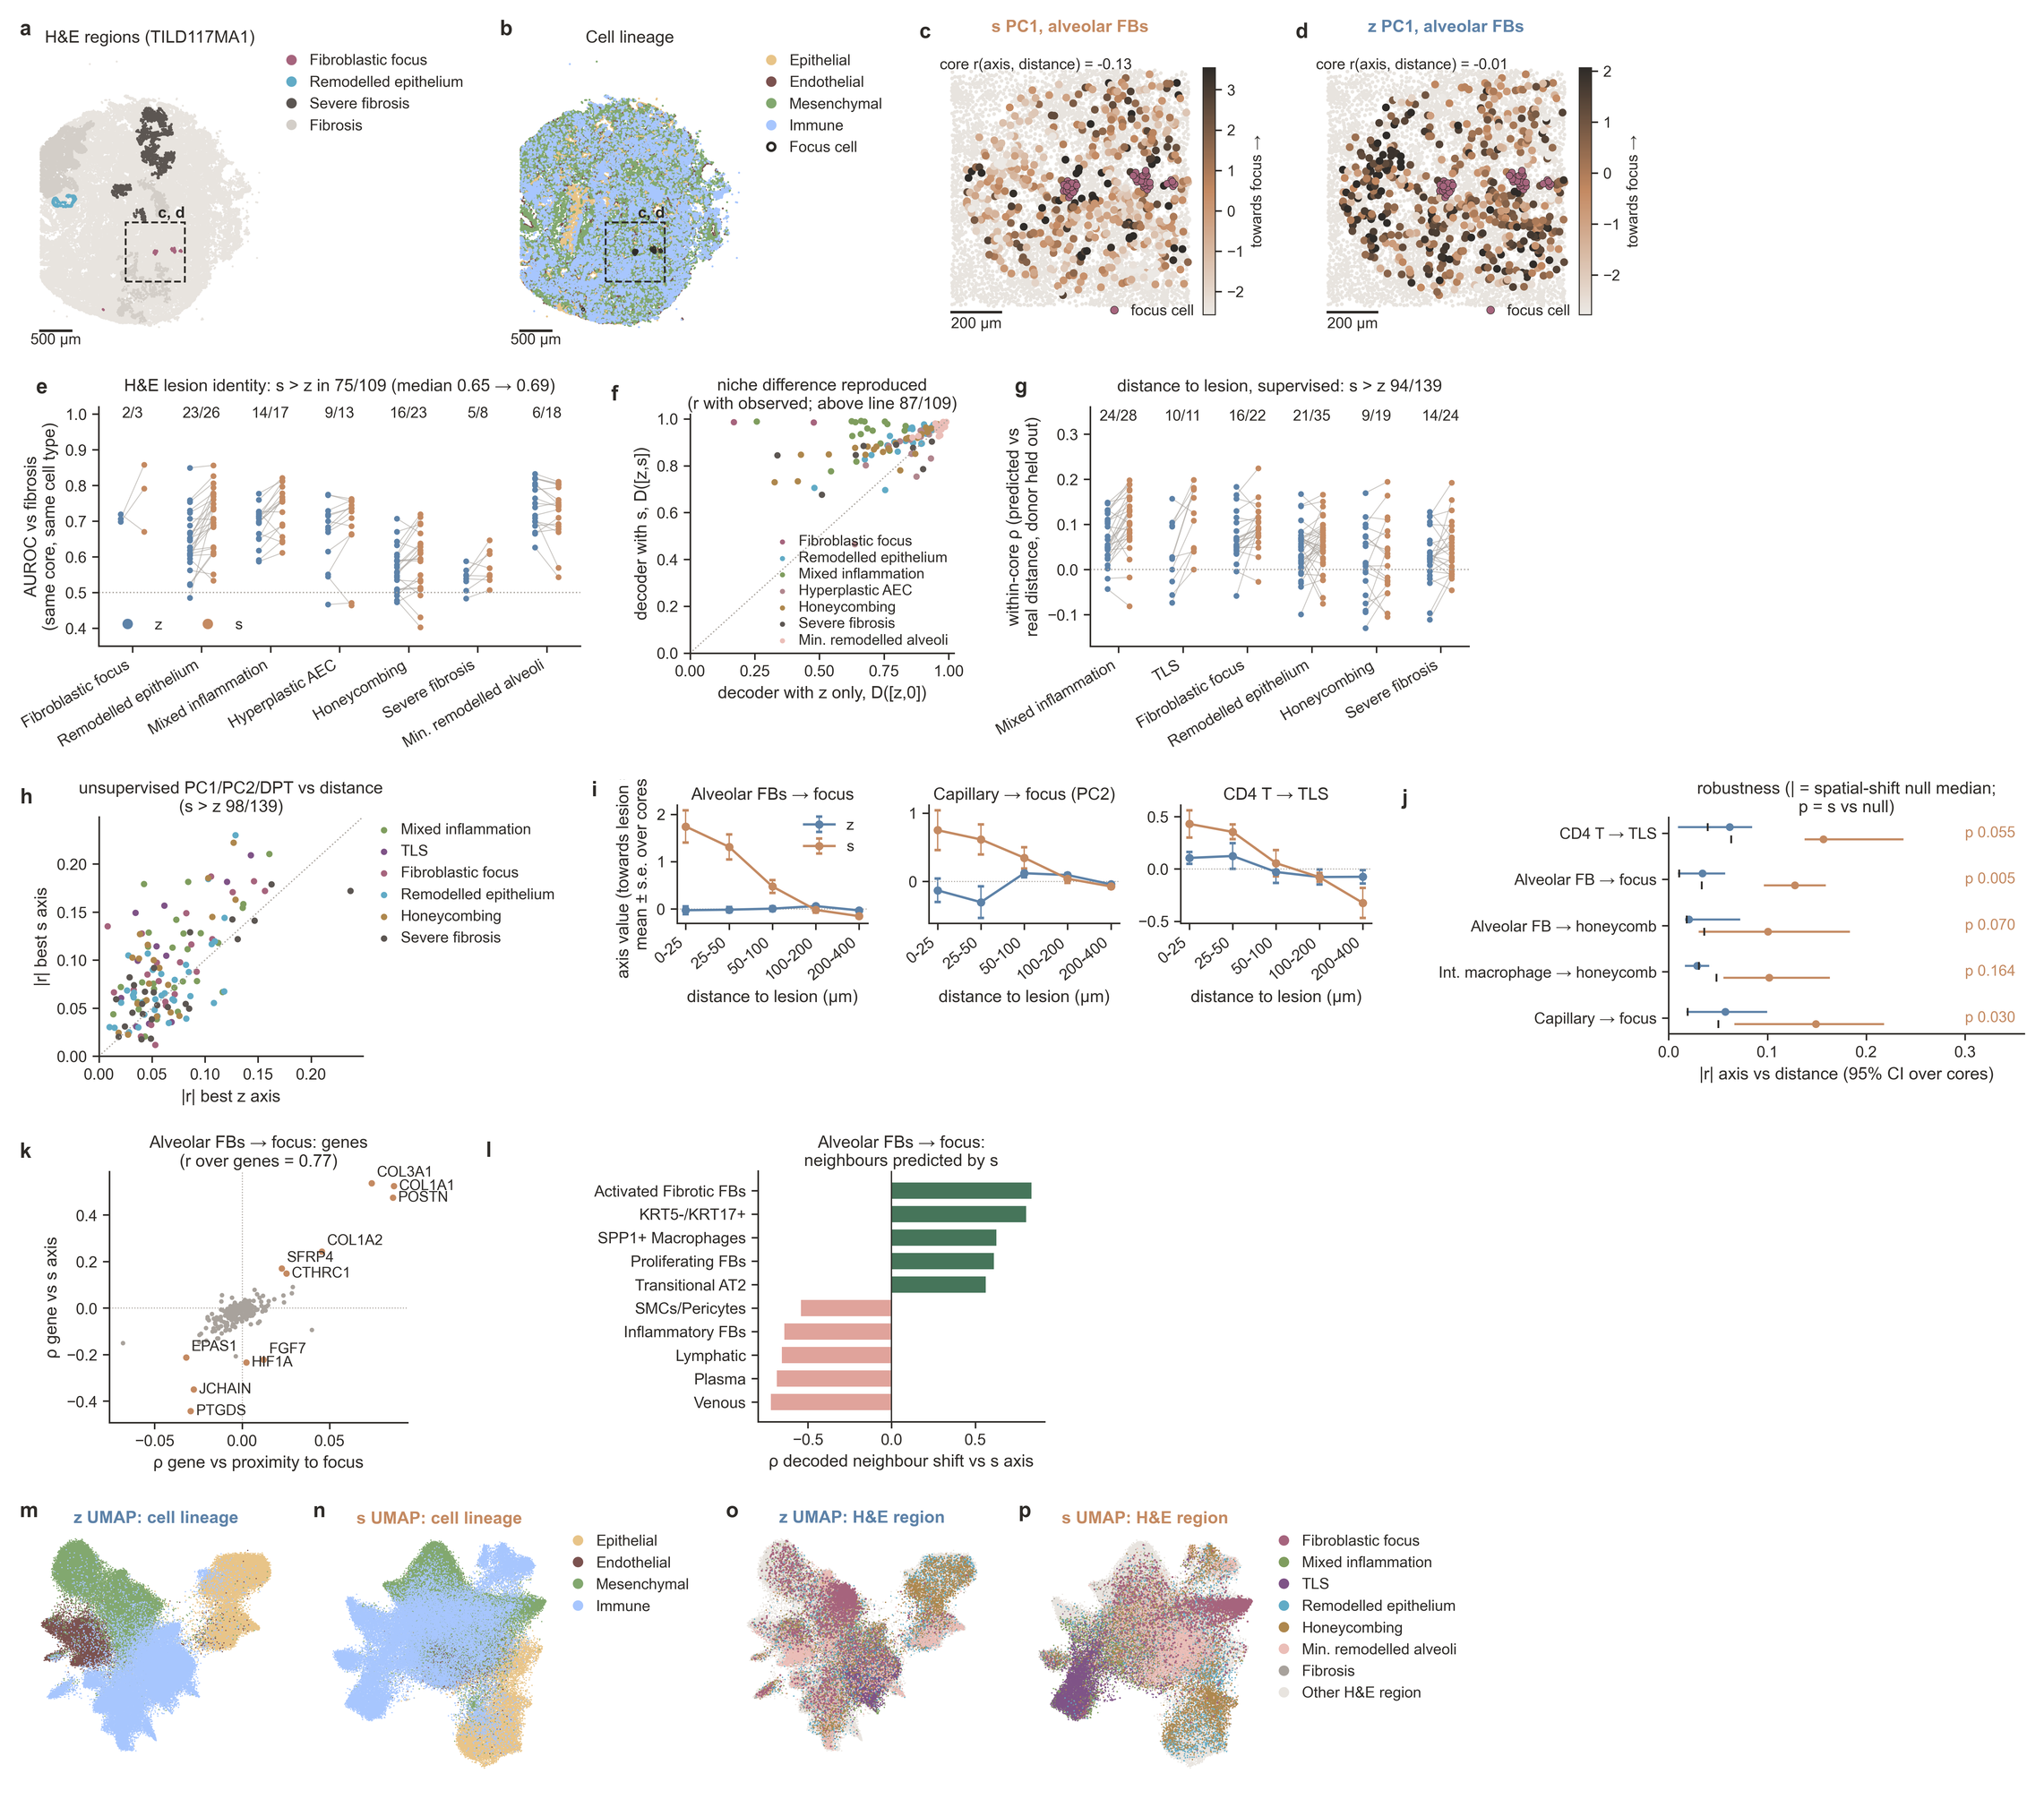

In [9]:
show(H / 'figures_paper/fibrosis/Fibrosis_lesion_gradient_full.png')